# 03 Xgboost


## Imports and dataset


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve
)

In [ ]:
from pathlib import Path

project_root = Path.cwd().resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent

data_path = project_root / 'data' / 'raw' / 'PS_20174392719_1491204439457_log.csv'
if not data_path.is_file():
    raise FileNotFoundError(f'Download the PaySim CSV and place it at {data_path}')

df = pd.read_csv(data_path)


In [4]:
df[['step', 'type', 'amount', 'isFraud']]

,step,type,amount,isFraud
0,1,PAYMENT,9839.64,0
1,1,PAYMENT,1864.28,0
2,1,TRANSFER,181.00,1
3,1,CASH_OUT,181.00,1
4,1,PAYMENT,11668.14,0
...,...,...,...,...
6362615,743,CASH_OUT,339682.13,1
6362616,743,TRANSFER,6311409.28,1
6362617,743,CASH_OUT,6311409.28,1
6362618,743,TRANSFER,850002.52,1


## Chronological train, validation, and test split


In [5]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

In [6]:
df['step'].iloc[train_end]

np.int64(323)

In [7]:
df['step'].iloc[val_end]

np.int64(378)

In [8]:
train_df = df[df['step'] < 323].copy()

val_df = df[(df['step'] >= 323) & (df['step'] < 378)].copy()

test_df = df[df['step'] >= 378].copy()

## Features and preprocessing


In [9]:
features = ['step', 'type', 'amount']
target = 'isFraud'

In [10]:
X_train, X_val, X_test = train_df[features], val_df[features], test_df[features]
y_train, y_val, y_test = train_df[target], val_df[target], test_df[target]

In [11]:
numeric_features = ['step', 'amount']
categorical_features = ['type']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)
preprocessor

ColumnTransformer(transformers=[('num', 'passthrough', ['step', 'amount']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['type'])])

## Baseline XGBoost


In [12]:
model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
                            n_estimators=200,
                            max_depth=4,
                            learning_rate=0.05,
                            subsample=0.8,
                            objective='binary:logistic',
                            tree_method='hist',
                            eval_metric='aucpr',
                            random_state=42,
                            n_jobs=-1
                        )
)])
model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['step', 'amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_ca...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [13]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['step', 'amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_ca...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [14]:
y_val_pred = model.predict(X_val)
y_val_proba = model.predict_proba(X_val)[:, 1]

In [15]:
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

print("Average Precision:", average_precision_score(y_val, y_val_proba))

print("ROC-AUC:", roc_auc_score(y_val, y_val_proba))

Confusion Matrix:
[[972598      5]
 [   498     72]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    972603
           1       0.94      0.13      0.22       570

    accuracy                           1.00    973173
   macro avg       0.97      0.56      0.61    973173
weighted avg       1.00      1.00      1.00    973173

Average Precision: 0.154028584079484
ROC-AUC: 0.9137141078694395


In [16]:
thresholds = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5]

for threshold in thresholds:
    y_pred = (y_val_proba >= threshold).astype(int)

    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    f1 = f1_score(y_val, y_pred, zero_division=0)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    print(
        f"Threshold: {threshold:.3f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f} | "
        f"TP: {tp} | FP: {fp} | "
        f"FN: {fn} | TN: {tn}"
    )

Threshold: 0.050 | Precision: 0.8416 | Recall: 0.1491 | F1: 0.2534 | TP: 85 | FP: 16 | FN: 485 | TN: 972587
Threshold: 0.100 | Precision: 0.8416 | Recall: 0.1491 | F1: 0.2534 | TP: 85 | FP: 16 | FN: 485 | TN: 972587
Threshold: 0.200 | Precision: 0.8416 | Recall: 0.1491 | F1: 0.2534 | TP: 85 | FP: 16 | FN: 485 | TN: 972587
Threshold: 0.300 | Precision: 0.9146 | Recall: 0.1316 | F1: 0.2301 | TP: 75 | FP: 7 | FN: 495 | TN: 972596
Threshold: 0.400 | Precision: 0.9146 | Recall: 0.1316 | F1: 0.2301 | TP: 75 | FP: 7 | FN: 495 | TN: 972596
Threshold: 0.500 | Precision: 0.9351 | Recall: 0.1263 | F1: 0.2226 | TP: 72 | FP: 5 | FN: 498 | TN: 972598


## Class weights and validation experiments


In [17]:
weighted_model_10 = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    scale_pos_weight=10,
    objective='binary:logistic',
    tree_method='hist',
    eval_metric='aucpr',
    random_state=42,
    n_jobs=-1
))]
)
weighted_model_10

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['step', 'amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_ca...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [18]:
weighted_model_10.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['step', 'amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_ca...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [19]:
y_val_pred_weighted_10 = weighted_model_10.predict(X_val)
y_val_proba_weighted_10 = weighted_model_10.predict_proba(X_val)[:, 1]

In [20]:
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_weighted_10))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_weighted_10, zero_division=0))

print("Average Precision:", average_precision_score(y_val, y_val_proba_weighted_10))

print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_weighted_10))

Confusion Matrix:
[[972587     16]
 [   485     85]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    972603
           1       0.84      0.15      0.25       570

    accuracy                           1.00    973173
   macro avg       0.92      0.57      0.63    973173
weighted avg       1.00      1.00      1.00    973173

Average Precision: 0.16226626869478036
ROC-AUC: 0.9161228988853226


In [21]:
weighted_model_100 = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    scale_pos_weight=100,
    objective='binary:logistic',
    tree_method='hist',
    eval_metric='aucpr',
    random_state=42,
    n_jobs=-1
))]
)
weighted_model_100

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['step', 'amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_ca...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [22]:
weighted_model_100.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['step', 'amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_ca...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [23]:
y_val_pred_weighted_100 = weighted_model_100.predict(X_val)
y_val_proba_weighted_100 = weighted_model_100.predict_proba(X_val)[:, 1]

In [24]:
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_weighted_100))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_weighted_100, zero_division=0))

print("Average Precision:", average_precision_score(y_val, y_val_proba_weighted_100))

print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_weighted_100))

Confusion Matrix:
[[963864   8739]
 [   406    164]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00    972603
           1       0.02      0.29      0.03       570

    accuracy                           0.99    973173
   macro avg       0.51      0.64      0.51    973173
weighted avg       1.00      0.99      0.99    973173

Average Precision: 0.16088635045515018
ROC-AUC: 0.9141680191144144


In [25]:
thresholds = [0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99]

results = []

for threshold in thresholds:
    y_pred = (y_val_proba_weighted_100 >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        'threshold': threshold,
        'precision': precision_score(y_val, y_pred, zero_division=0),
        'recall': recall_score(y_val, y_pred, zero_division=0),
        'f1': f1_score(y_val, y_pred, zero_division=0),
        'TP': tp,
        'FP': fp,
        'FN': fn
    })

threshold_results = pd.DataFrame(results)
threshold_results

,threshold,precision,recall,f1,TP,FP,FN
0,0.10,0.004315,0.735088,0.008581,419,96673,151
1,0.30,0.011784,0.368421,0.022837,210,17611,360
2,0.50,0.018421,0.287719,0.034625,164,8739,406
3,0.70,0.699187,0.150877,0.248196,86,37,484
4,0.80,0.841584,0.149123,0.253353,85,16,485
5,0.90,0.940299,0.110526,0.197802,63,4,507
6,0.95,0.000000,0.000000,0.000000,0,0,570
7,0.99,0.000000,0.000000,0.000000,0,0,570


In [26]:
classifier = weighted_model_10.named_steps['classifier']
feature_names = (
    weighted_model_10.named_steps['preprocessor']
    .get_feature_names_out()
)
importances = classifier.feature_importances_

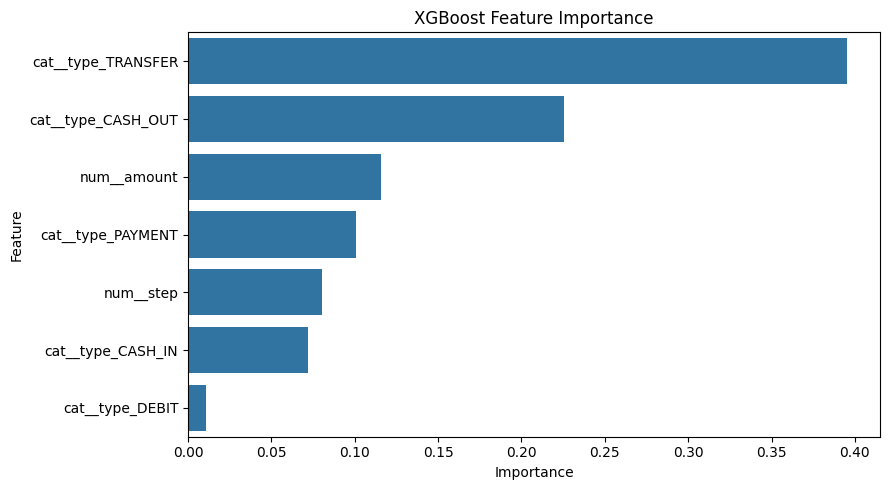

In [27]:
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x='importance',
    y='feature'
)

plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

## Feature and hyperparameter experiments


In [28]:
numeric_features = ['amount']
categorical_features = ['type']

preprocessor_fa = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)
preprocessor_fa

ColumnTransformer(transformers=[('num', 'passthrough', ['amount']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['type'])])

In [29]:
model_fa = Pipeline(
    steps=[
        ('preprocessor', preprocessor_fa),
        ('classifier', XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    scale_pos_weight=10,
    objective='binary:logistic',
    tree_method='hist',
    eval_metric='aucpr',
    random_state=42,
    n_jobs=-1
))]
)
model_fa

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categoric...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [30]:
model_fa.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['amount']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categoric...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [31]:
y_val_pred_fa = model_fa.predict(X_val)
y_val_proba_fa = model_fa.predict_proba(X_val)[:, 1]

In [32]:
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_fa))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_fa, zero_division=0))

print("Average Precision:", average_precision_score(y_val, y_val_proba_fa))

print("ROC-AUC:", roc_auc_score(y_val, y_val_proba_fa))

Confusion Matrix:
[[972587     16]
 [   485     85]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    972603
           1       0.84      0.15      0.25       570

    accuracy                           1.00    973173
   macro avg       0.92      0.57      0.63    973173
weighted avg       1.00      1.00      1.00    973173

Average Precision: 0.1609485742334661
ROC-AUC: 0.91484601161892


In [33]:
depth_results = []
depth_models = {}

for depth in [3, 6]:

    depth_model = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', XGBClassifier(
                n_estimators=200,
                max_depth=depth,
                learning_rate=0.05,
                subsample=0.8,
                scale_pos_weight=10,
                objective='binary:logistic',
                tree_method='hist',
                eval_metric='aucpr',
                random_state=42,
                n_jobs=-1
            ))
        ]
    )

    depth_model.fit(X_train, y_train)

    y_pred = depth_model.predict(X_val)
    y_proba = depth_model.predict_proba(X_val)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    depth_results.append({
        'max_depth': depth,
        'precision': precision_score(y_val, y_pred, zero_division=0),
        'recall': recall_score(y_val, y_pred, zero_division=0),
        'f1': f1_score(y_val, y_pred, zero_division=0),
        'average_precision': average_precision_score(y_val, y_proba),
        'roc_auc': roc_auc_score(y_val, y_proba),
        'TP': tp,
        'FP': fp,
        'FN': fn
    })

    depth_models[depth] = depth_model

depth_results_df = pd.DataFrame(depth_results)
depth_results_df

,max_depth,precision,recall,f1,average_precision,roc_auc,TP,FP,FN
0,3,0.841584,0.149123,0.253353,0.163000,0.914866,85,16,485
1,6,0.841584,0.149123,0.253353,0.164086,0.913292,85,16,485


In [34]:
depth_4_pred = weighted_model_10.predict(X_val)
depth_4_proba = weighted_model_10.predict_proba(X_val)[:, 1]

tn, fp, fn, tp = confusion_matrix(
    y_val, depth_4_pred, labels=[0, 1]
).ravel()

depth_4_result = {
    'max_depth': 4,
    'precision': precision_score(y_val, depth_4_pred, zero_division=0),
    'recall': recall_score(y_val, depth_4_pred, zero_division=0),
    'f1': f1_score(y_val, depth_4_pred, zero_division=0),
    'average_precision': average_precision_score(y_val, depth_4_proba),
    'roc_auc': roc_auc_score(y_val, depth_4_proba),
    'TP': tp,
    'FP': fp,
    'FN': fn
}

depth_results_df = pd.concat(
    [depth_results_df, pd.DataFrame([depth_4_result])],
    ignore_index=True
).sort_values('max_depth').reset_index(drop=True)

depth_models[4] = weighted_model_10

depth_results_df

,max_depth,precision,recall,f1,average_precision,roc_auc,TP,FP,FN
0,3,0.841584,0.149123,0.253353,0.163000,0.914866,85,16,485
1,4,0.841584,0.149123,0.253353,0.162266,0.916123,85,16,485
2,6,0.841584,0.149123,0.253353,0.164086,0.913292,85,16,485


In [35]:
tree_results = []
tree_models = {}

for n_trees in [100, 400, 600]:

    tree_model = Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', XGBClassifier(
                n_estimators=n_trees,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                scale_pos_weight=10,
                objective='binary:logistic',
                tree_method='hist',
                eval_metric='aucpr',
                random_state=42,
                n_jobs=-1
            ))
        ]
    )

    tree_model.fit(X_train, y_train)

    y_pred = tree_model.predict(X_val)
    y_proba = tree_model.predict_proba(X_val)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    tree_results.append({
        'n_estimators': n_trees,
        'precision': precision_score(y_val, y_pred, zero_division=0),
        'recall': recall_score(y_val, y_pred, zero_division=0),
        'f1': f1_score(y_val, y_pred, zero_division=0),
        'average_precision': average_precision_score(y_val, y_proba),
        'roc_auc': roc_auc_score(y_val, y_proba),
        'TP': tp,
        'FP': fp,
        'FN': fn
    })

    tree_models[n_trees] = tree_model

tree_results_df = pd.DataFrame(tree_results)

# Include the previously trained 200-tree model
baseline_pred = weighted_model_10.predict(X_val)
baseline_proba = weighted_model_10.predict_proba(X_val)[:, 1]

tn, fp, fn, tp = confusion_matrix(
    y_val, baseline_pred, labels=[0, 1]
).ravel()

baseline_result = {
    'n_estimators': 200,
    'precision': precision_score(y_val, baseline_pred, zero_division=0),
    'recall': recall_score(y_val, baseline_pred, zero_division=0),
    'f1': f1_score(y_val, baseline_pred, zero_division=0),
    'average_precision': average_precision_score(y_val, baseline_proba),
    'roc_auc': roc_auc_score(y_val, baseline_proba),
    'TP': tp,
    'FP': fp,
    'FN': fn
}

tree_results_df = pd.concat(
    [tree_results_df, pd.DataFrame([baseline_result])],
    ignore_index=True
).sort_values('n_estimators').reset_index(drop=True)

tree_models[200] = weighted_model_10

tree_results_df

,n_estimators,precision,recall,f1,average_precision,roc_auc,TP,FP,FN
0,100,0.841584,0.149123,0.253353,0.162623,0.914648,85,16,485
1,200,0.841584,0.149123,0.253353,0.162266,0.916123,85,16,485
2,400,0.914634,0.131579,0.230061,0.154104,0.909174,75,7,495
3,600,0.580153,0.133333,0.216833,0.141229,0.902654,76,55,494


In [36]:
X_train_fe = X_train.copy()
X_val_fe = X_val.copy()

X_train_fe['high_amount_cashout'] = ((X_train_fe['type'] == 'CASH_OUT') & (X_train_fe['amount'] > 1_000_000)).astype(int)
X_val_fe['high_amount_cashout'] = ((X_val_fe['type'] == 'CASH_OUT') & (X_val_fe['amount'] > 1_000_000)).astype(int)

In [37]:
numeric_features_fe = ['step', 'amount', 'high_amount_cashout']
categorical_features_fe = ['type']

preprocessor_fe = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features_fe),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features_fe)
    ]
)

model_fe = Pipeline(
    steps=[
        ('preprocessor', preprocessor_fe),
        ('classifier', XGBClassifier(
            n_estimators=100,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            scale_pos_weight=10,
            objective='binary:logistic',
            tree_method='hist',
            eval_metric='aucpr',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

model_fe.fit(X_train_fe, y_train)

y_val_pred_fe = model_fe.predict(X_val_fe)
y_val_proba_fe = model_fe.predict_proba(X_val_fe)[:, 1]

tn, fp, fn, tp = confusion_matrix(
    y_val, y_val_pred_fe, labels=[0, 1]
).ravel()

print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_fe))

print("\nClassification Report:")
print(classification_report(
    y_val, y_val_pred_fe, zero_division=0
))

print("Average Precision:",
      average_precision_score(y_val, y_val_proba_fe))

print("ROC-AUC:",
      roc_auc_score(y_val, y_val_proba_fe))

Confusion Matrix:
[[972587     16]
 [   485     85]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    972603
           1       0.84      0.15      0.25       570

    accuracy                           1.00    973173
   macro avg       0.92      0.57      0.63    973173
weighted avg       1.00      1.00      1.00    973173

Average Precision: 0.16291505123277428
ROC-AUC: 0.9123715043863753


In [38]:
comparison_df = pd.DataFrame([
    {
        'model': 'Baseline XGBoost',
        'average_precision': 0.162623,
        'roc_auc': 0.914648,
        'precision': 0.841584,
        'recall': 0.149123,
        'TP': 85,
        'FP': 16
    },
    {
        'model': 'Feature-Engineered XGBoost',
        'average_precision': average_precision_score(y_val, y_val_proba_fe),
        'roc_auc': roc_auc_score(y_val, y_val_proba_fe),
        'precision': precision_score(y_val, y_val_pred_fe, zero_division=0),
        'recall': recall_score(y_val, y_val_pred_fe, zero_division=0),
        'TP': tp,
        'FP': fp
    }
])

comparison_df

,model,average_precision,roc_auc,precision,recall,TP,FP
0,Baseline XGBoost,0.162623,0.914648,0.841584,0.149123,85,16
1,Feature-Engineered XGBoost,0.162915,0.912372,0.841584,0.149123,85,16


## Validation threshold selection


In [39]:
from sklearn.metrics import precision_recall_curve

# Retrieve the 100-tree model
final_candidate = tree_models[100]

# Validation probabilities
val_proba = final_candidate.predict_proba(X_val)[:, 1]

# Calculate precision and recall across thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val, val_proba
)

# The last precision/recall point has no corresponding threshold
threshold_df = pd.DataFrame({
    'threshold': thresholds,
    'precision': precision[:-1],
    'recall': recall[:-1]
})

# Keep thresholds achieving at least 50% precision
eligible = threshold_df[
    threshold_df['precision'] >= 0.50
]

# Select the threshold with highest recall
if eligible.empty:
    print("No threshold meets the precision requirement.")
else:
    best_row = eligible.sort_values(
        ['recall', 'precision'],
        ascending=[False, False]
    ).iloc[0]

    best_threshold = float(best_row['threshold'])

    print("Selected threshold:", best_threshold)
    print("Validation precision:", best_row['precision'])
    print("Validation recall:", best_row['recall'])

Selected threshold: 0.42458799481391907
Validation precision: 0.5595238095238095
Validation recall: 0.1649122807017544


In [40]:
precision_targets = [0.50, 0.30, 0.20, 0.10, 0.05]

results = []

for target in precision_targets:
    eligible = threshold_df[
        threshold_df['precision'] >= target
    ]

    if not eligible.empty:
        best = eligible.sort_values(
            ['recall', 'precision'],
            ascending=[False, False]
        ).iloc[0]

        results.append({
            'minimum_precision': target,
            'threshold': best['threshold'],
            'precision': best['precision'],
            'recall': best['recall']
        })

pd.DataFrame(results)

,minimum_precision,threshold,precision,recall
0,0.50,0.424588,0.559524,0.164912
1,0.30,0.424588,0.559524,0.164912
2,0.20,0.228521,0.215010,0.185965
3,0.10,0.228521,0.215010,0.185965
4,0.05,0.152183,0.059651,0.215789


## Hour-of-day feature and final model


In [41]:
X_train_hour = X_train.copy()
X_val_hour = X_val.copy()

X_train_hour['hour_of_day'] = (X_train_hour['step'] - 1) % 24
X_val_hour['hour_of_day'] = (X_val_hour['step'] - 1) % 24

In [42]:
numeric_features_hour = ['step', 'amount', 'hour_of_day']
categorical_features_hour = ['type']

preprocessor_hour = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numeric_features_hour),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features_hour)
    ]
)

model_hour = Pipeline(
    steps=[
        ('preprocessor', preprocessor_hour),
        ('classifier', XGBClassifier(
            n_estimators=100,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            scale_pos_weight=10,
            objective='binary:logistic',
            tree_method='hist',
            eval_metric='aucpr',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [43]:
# Train
model_hour.fit(X_train_hour, y_train)

# Validation predictions
y_val_pred_hour = model_hour.predict(X_val_hour)
y_val_proba_hour = model_hour.predict_proba(X_val_hour)[:, 1]

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_val, y_val_pred_hour, labels=[0, 1]
).ravel()

# Evaluation
hour_results = {
    'model': 'Hour-of-Day XGBoost',
    'average_precision': average_precision_score(
        y_val, y_val_proba_hour
    ),
    'roc_auc': roc_auc_score(y_val, y_val_proba_hour),
    'precision': precision_score(
        y_val, y_val_pred_hour, zero_division=0
    ),
    'recall': recall_score(
        y_val, y_val_pred_hour, zero_division=0
    ),
    'f1': f1_score(
        y_val, y_val_pred_hour, zero_division=0
    ),
    'TP': tp,
    'FP': fp,
    'FN': fn
}

pd.DataFrame([hour_results])

,model,average_precision,roc_auc,precision,recall,f1,TP,FP,FN
0,Hour-of-Day XGBoost,0.388916,0.94389,0.753676,0.359649,0.486936,205,67,365


In [44]:
baseline_model = tree_models[100]

baseline_pred = baseline_model.predict(X_val)
baseline_proba = baseline_model.predict_proba(X_val)[:, 1]

tn, fp, fn, tp = confusion_matrix(
    y_val, baseline_pred, labels=[0, 1]
).ravel()

baseline_results = {
    'model': 'Baseline XGBoost',
    'average_precision': average_precision_score(
        y_val, baseline_proba
    ),
    'roc_auc': roc_auc_score(y_val, baseline_proba),
    'precision': precision_score(
        y_val, baseline_pred, zero_division=0
    ),
    'recall': recall_score(
        y_val, baseline_pred, zero_division=0
    ),
    'f1': f1_score(
        y_val, baseline_pred, zero_division=0
    ),
    'TP': tp,
    'FP': fp,
    'FN': fn
}

comparison_hour_df = pd.DataFrame([
    baseline_results,
    hour_results
])

comparison_hour_df

,model,average_precision,roc_auc,precision,recall,f1,TP,FP,FN
0,Baseline XGBoost,0.162623,0.914648,0.841584,0.149123,0.253353,85,16,485
1,Hour-of-Day XGBoost,0.388916,0.943890,0.753676,0.359649,0.486936,205,67,365


In [45]:
hour_analysis = train_df.copy()

hour_analysis['hour_of_day'] = (
    (hour_analysis['step'] - 1) % 24
)

hour_summary = (
    hour_analysis.groupby('hour_of_day')['isFraud']
    .agg(['count', 'sum', 'mean'])
    .rename(columns={
        'count': 'total_transactions',
        'sum': 'fraud_count',
        'mean': 'fraud_rate'
    })
)

hour_summary['fraud_rate'] *= 100

hour_summary

,total_transactions,fraud_count,fraud_rate
hour_of_day,,,
0,20464,170,0.830727
1,6047,158,2.612866
2,1065,126,11.830986
3,665,110,16.541353
4,803,144,17.932752
5,1788,150,8.389262
6,6975,150,2.150538
7,21251,166,0.781140
8,225861,183,0.081023


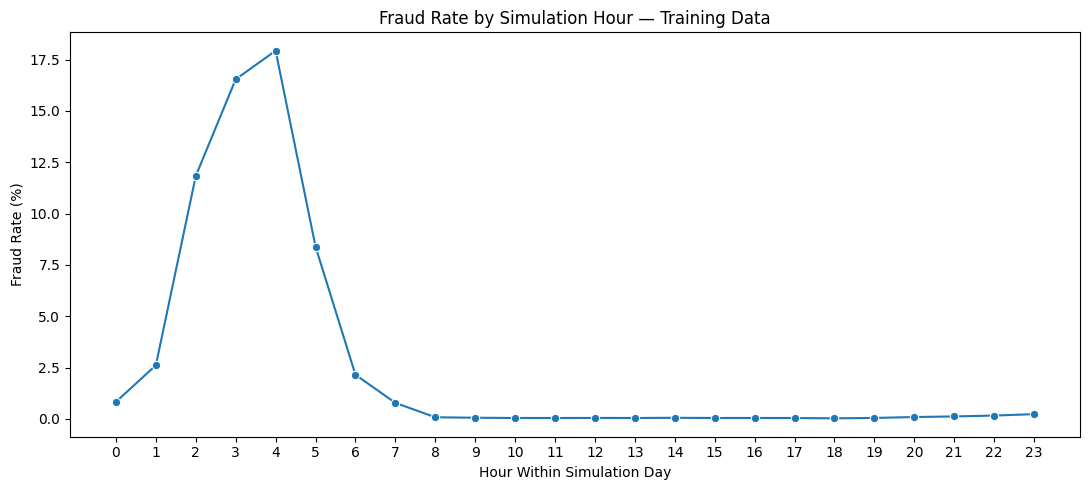

In [46]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=hour_summary.reset_index(),
    x='hour_of_day',
    y='fraud_rate',
    marker='o'
)

plt.title('Fraud Rate by Simulation Hour — Training Data')
plt.xlabel('Hour Within Simulation Day')
plt.ylabel('Fraud Rate (%)')
plt.xticks(range(24))

plt.tight_layout()
plt.show()

## Final validation threshold


In [47]:
from sklearn.metrics import precision_recall_curve

# Validation probabilities
hour_val_proba = model_hour.predict_proba(X_val_hour)[:, 1]

# Precision-recall curve
precision, recall, thresholds = precision_recall_curve(
    y_val, hour_val_proba
)

# Build threshold comparison
threshold_hour_df = pd.DataFrame({
    'threshold': thresholds,
    'precision': precision[:-1],
    'recall': recall[:-1]
})

# Filter by minimum precision
eligible = threshold_hour_df[
    threshold_hour_df['precision'] >= 0.50
]

if eligible.empty:
    print("No threshold meets the precision requirement.")
else:
    best_row = eligible.sort_values(
        ['recall', 'precision'],
        ascending=[False, False]
    ).iloc[0]

    best_threshold_hour = float(best_row['threshold'])

    print("Selected threshold:", best_threshold_hour)
    print("Validation precision:", best_row['precision'])
    print("Validation recall:", best_row['recall'])

Selected threshold: 0.30614158511161804
Validation precision: 0.5558312655086849
Validation recall: 0.3929824561403509


## Held-out test evaluation


In [48]:
# Create test features
X_test_hour = X_test.copy()

X_test_hour['hour_of_day'] = (
    (X_test_hour['step'] - 1) % 24
)

# Use the previously selected threshold
final_threshold = best_threshold_hour

# Generate test probabilities
y_test_proba = model_hour.predict_proba(X_test_hour)[:, 1]

# Apply the fixed threshold
y_test_pred = (y_test_proba >= final_threshold).astype(int)

In [49]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_test_pred, zero_division=0
))

print("Average Precision:",
      average_precision_score(y_test, y_test_proba))

print("ROC-AUC:",
      roc_auc_score(y_test, y_test_proba))

print("F1-score:",
      f1_score(y_test, y_test_pred, zero_division=0))

Confusion Matrix:
[[948382   3352]
 [  2219   1791]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    951734
           1       0.35      0.45      0.39      4010

    accuracy                           0.99    955744
   macro avg       0.67      0.72      0.69    955744
weighted avg       0.99      0.99      0.99    955744

Average Precision: 0.36044756747957307
ROC-AUC: 0.9500613654823302
F1-score: 0.3913470993117011


## Error analysis


In [50]:
error_df = X_test_hour.copy()

error_df['actual'] = y_test.to_numpy()
error_df['predicted'] = y_test_pred
error_df['fraud_probability'] = y_test_proba

false_negatives = error_df[
    (error_df['actual'] == 1) &
    (error_df['predicted'] == 0)
]

print("False Negatives by Transaction Type:")
print(false_negatives['type'].value_counts())

False Negatives by Transaction Type:
type
TRANSFER    1316
CASH_OUT     903
Name: count, dtype: int64


In [51]:
fraud_df = error_df[error_df['actual'] == 1].copy()

type_recall = (
    fraud_df.groupby('type')['predicted']
    .agg(['count', 'sum', 'mean'])
    .rename(columns={
        'count': 'Total Fraud',
        'sum': 'Detected Fraud (TP)',
        'mean': 'Recall (%)'
    })
)

type_recall['Missed Fraud (FN)'] = (
    type_recall['Total Fraud'] -
    type_recall['Detected Fraud (TP)']
)

type_recall['Recall (%)'] *= 100

type_recall

,Total Fraud,Detected Fraud (TP),Recall (%),Missed Fraud (FN)
type,,,,
CASH_OUT,2005,1102,54.962594,903
TRANSFER,2005,689,34.364090,1316


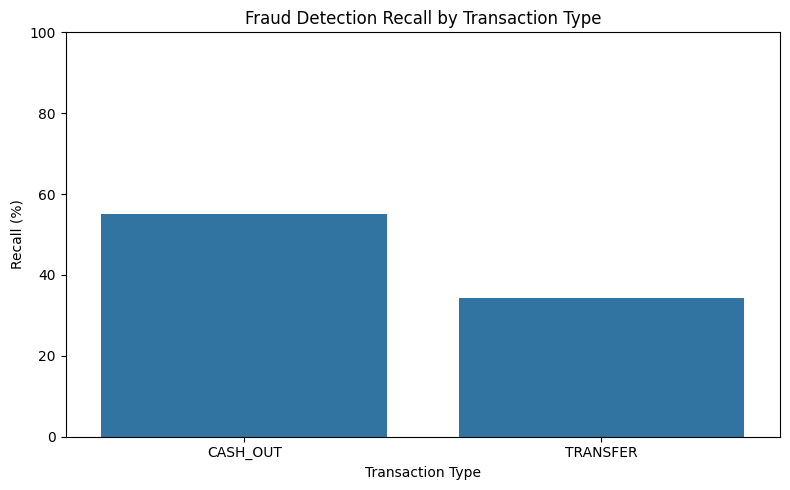

In [52]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=type_recall.reset_index(),
    x='type',
    y='Recall (%)'
)

plt.title('Fraud Detection Recall by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Recall (%)')
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [53]:
bins = [
    0,
    10_000,
    50_000,
    100_000,
    500_000,
    1_000_000,
    float('inf')
]

labels = [
    '0–10K',
    '10K–50K',
    '50K–100K',
    '100K–500K',
    '500K–1M',
    '>1M'
]

fraud_df = error_df[error_df['actual'] == 1].copy()

fraud_df['amount_bin'] = pd.cut(
    fraud_df['amount'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

In [54]:
amount_recall = (
    fraud_df.groupby('amount_bin', observed=True)['predicted']
    .agg(['count', 'sum', 'mean'])
    .rename(columns={
        'count': 'Total Fraud',
        'sum': 'Detected Fraud (TP)',
        'mean': 'Recall (%)'
    })
)

amount_recall['Missed Fraud (FN)'] = (
    amount_recall['Total Fraud'] -
    amount_recall['Detected Fraud (TP)']
)

amount_recall['Recall (%)'] *= 100

amount_recall

,Total Fraud,Detected Fraud (TP),Recall (%),Missed Fraud (FN)
amount_bin,,,,
0–10K,131,38,29.007634,93
10K–50K,336,87,25.892857,249
50K–100K,320,89,27.812500,231
100K–500K,1286,384,29.860031,902
500K–1M,568,265,46.654930,303
>1M,1369,928,67.786706,441


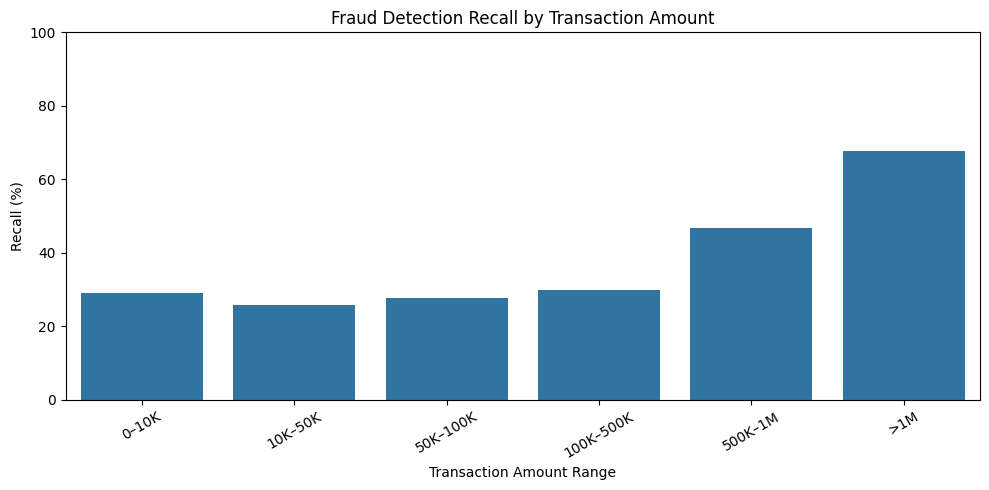

In [55]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=amount_recall.reset_index(),
    x='amount_bin',
    y='Recall (%)'
)

plt.title('Fraud Detection Recall by Transaction Amount')
plt.xlabel('Transaction Amount Range')
plt.ylabel('Recall (%)')
plt.ylim(0, 100)
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [56]:
fraud_df = error_df[error_df['actual'] == 1].copy()

hour_recall = (
    fraud_df.groupby('hour_of_day')['predicted']
    .agg(['count', 'sum', 'mean'])
    .rename(columns={
        'count': 'Total Fraud',
        'sum': 'Detected Fraud (TP)',
        'mean': 'Recall (%)'
    })
)

hour_recall['Missed Fraud (FN)'] = (
    hour_recall['Total Fraud'] -
    hour_recall['Detected Fraud (TP)']
)

hour_recall['Recall (%)'] *= 100

hour_recall

,Total Fraud,Detected Fraud (TP),Recall (%),Missed Fraud (FN)
hour_of_day,,,,
0,164,116,70.731707,48
1,190,163,85.789474,27
2,176,176,100.000000,0
3,148,148,100.000000,0
4,198,198,100.000000,0
5,184,184,100.000000,0
6,152,152,100.000000,0
7,190,190,100.000000,0
8,140,24,17.142857,116


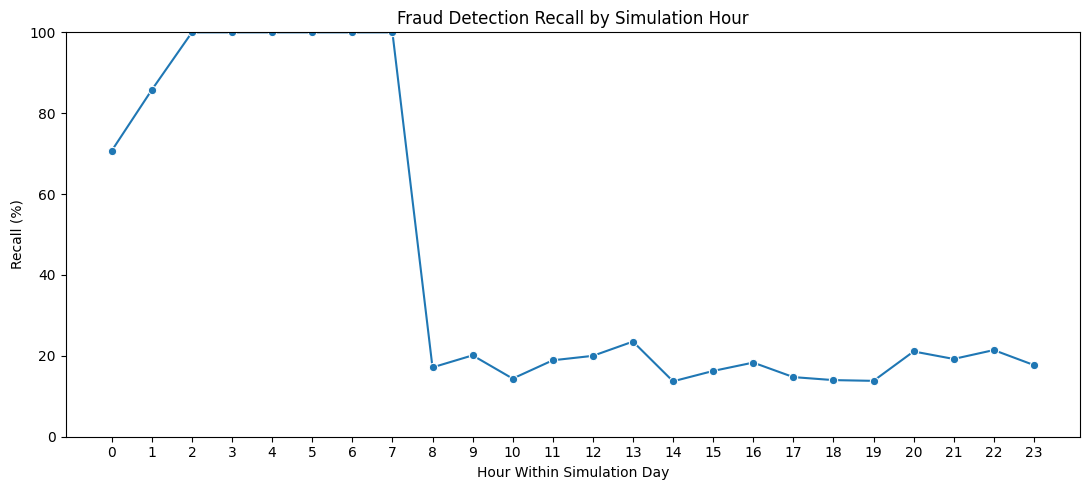

In [57]:
plt.figure(figsize=(11, 5))

sns.lineplot(
    data=hour_recall.reset_index(),
    x='hour_of_day',
    y='Recall (%)',
    marker='o'
)

plt.title('Fraud Detection Recall by Simulation Hour')
plt.xlabel('Hour Within Simulation Day')
plt.ylabel('Recall (%)')
plt.xticks(range(24))
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

## Save and verify the trained model


In [ ]:
import joblib

model_dir = project_root / 'models'
model_dir.mkdir(exist_ok=True)
joblib.dump(model_hour, model_dir / 'fraud_detection_xgboost.joblib')
joblib.dump(best_threshold_hour, model_dir / 'classification_threshold.joblib')
print('Model and threshold saved successfully!')


In [ ]:
loaded_model = joblib.load(
    model_dir / 'fraud_detection_xgboost.joblib'
)

loaded_threshold = joblib.load(
    model_dir / 'classification_threshold.joblib'
)

# Test on a small sample
sample = X_val_hour.head(10)

original_proba = model_hour.predict_proba(sample)[:, 1]
loaded_proba = loaded_model.predict_proba(sample)[:, 1]

# Verify probabilities match
print(
    "Predictions match:",
    np.allclose(original_proba, loaded_proba)
)

print("Loaded threshold:", loaded_threshold)

## Example inference function


In [ ]:
loaded_model = joblib.load(
    model_dir / 'fraud_detection_xgboost.joblib'
)

loaded_threshold = joblib.load(
    model_dir / 'classification_threshold.joblib'
)

def predict_fraud(step, transaction_type, amount):

    # Input DataFrame
    transaction = pd.DataFrame([{
        'step': step,
        'type': transaction_type,
        'amount': amount
    }])

    # Feature engineering
    transaction['hour_of_day'] = (
        (transaction['step'] - 1) % 24
    )

    # Predict fraud score
    fraud_score = float(
        loaded_model.predict_proba(transaction)[0, 1]
    )

    # Apply saved classification threshold
    prediction = int(fraud_score >= loaded_threshold)

    return {
        'fraud_score': fraud_score,
        'prediction': prediction,
        'classification': (
            'Fraudulent' if prediction == 1 else 'Legitimate'
        )}

In [61]:
result = predict_fraud(
    step=325,
    transaction_type='TRANSFER',
    amount=500000
)

print(result)

{'fraud_score': 0.016032202169299126, 'prediction': 0, 'classification': 'Legitimate'}


In [62]:
sample = X_val.iloc[0]

result = predict_fraud(
    step=int(sample['step']),
    transaction_type=sample['type'],
    amount=float(sample['amount'])
)

expected_score = float(
    model_hour.predict_proba(
        X_val_hour.iloc[[0]]
    )[0, 1]
)

print("Inference score:", result['fraud_score'])
print("Expected score:", expected_score)

print(
    "Scores match:",
    np.isclose(result['fraud_score'], expected_score)
)

Inference score: 0.0008500313269905746
Expected score: 0.0008500313269905746
Scores match: True
